# Pima Indians Diabetes — Neural Network Experiments

## 0. Setup

In [1]:
import os, json, time, itertools, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             recall_score, precision_score, confusion_matrix, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

torch.set_num_threads(2)
COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
        "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
SEED = 42
OUT = "results"
os.makedirs(OUT, exist_ok=True)
os.makedirs("data", exist_ok=True)

PLOT_DIR = os.path.join(OUT, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

## 1. Data


In [2]:
DATA_PATH = "data/diabetes.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files
    up = files.upload()
    os.replace(next(iter(up)), DATA_PATH)

Saving diabetes.csv to diabetes.csv


In [3]:
# Membaca dataset
df = pd.read_csv(DATA_PATH)

# Pastikan semua kolom berisi data numerik
df = df.apply(pd.to_numeric, errors="raise")

# Validasi struktur dataset
assert df.shape[1] == len(COLS), (
    "Jumlah kolom dataset tidak sesuai."
)

assert df["Outcome"].isin([0, 1]).all(), (
    "Kolom Outcome harus berisi label 0 atau 1."
)

assert df[COLS[:-1]].notna().all().all(), (
    "Ada nilai kosong asli; periksa dataset."
)

print("Ukuran dataset:", df.shape)
print("\nDistribusi kelas Outcome:")
print(df["Outcome"].value_counts().sort_index())

# Nilai nol pada kolom fisiologis diperlakukan
# sebagai missing value sesuai protokol penelitian
for c in ZERO_AS_MISSING:
    df.loc[df[c] == 0, c] = np.nan

# Memisahkan fitur dan target
X_all = df.drop(columns="Outcome").values.astype(np.float32)
y_all = df["Outcome"].values.astype(np.float32)

# Hold-out test set: 20%, stratified
X_tr, X_te, y_tr, y_te = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    stratify=y_all,
    random_state=SEED
)

# Ringkasan data
info = {
    "n": len(df),
    "n_train": len(X_tr),
    "n_test": len(X_te),
    "pos_rate": float(y_all.mean()),
    "missing": {
        c: int(df[c].isna().sum())
        for c in ZERO_AS_MISSING
    }
}

json.dump(
    info,
    open(f"{OUT}/data_info.json", "w"),
    indent=1
)

print("\nRingkasan dataset:")
print(json.dumps(info, indent=1))

display(df.describe().T)

Ukuran dataset: (768, 9)

Distribusi kelas Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64

Ringkasan dataset:
{
 "n": 768,
 "n_train": 614,
 "n_test": 154,
 "pos_rate": 0.3489583432674408,
 "missing": {
  "Glucose": 5,
  "BloodPressure": 35,
  "SkinThickness": 227,
  "Insulin": 374,
  "BMI": 11
 }
}


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,763.0,121.686763,30.535641,44.000,99.00000,117.0000,141.00000,199.00
BloodPressure,733.0,72.405184,12.382158,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,541.0,29.153420,10.476982,7.000,22.00000,29.0000,36.00000,99.00
Insulin,394.0,155.548223,118.775855,14.000,76.25000,125.0000,190.00000,846.00
BMI,757.0,32.457464,6.924988,18.200,27.50000,32.3000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 2. Preprocessing & model

In [4]:
def prep(Xa, Xb):
    imp = SimpleImputer(strategy="median").fit(Xa)
    sc = StandardScaler().fit(imp.transform(Xa))
    f = lambda Z: sc.transform(imp.transform(Z)).astype(np.float32)
    return f(Xa), f(Xb)


class MLP(nn.Module):
    def __init__(self, d_in, hidden, act="relu", dropout=0.0, bn=False, residual=False):
        super().__init__()
        A = {"relu": nn.ReLU, "tanh": nn.Tanh, "elu": nn.ELU}[act]
        self.residual = residual
        layers, d = [], d_in
        for h in hidden:
            blk = [nn.Linear(d, h)]
            if bn: blk.append(nn.BatchNorm1d(h))
            blk.append(A())
            if dropout > 0: blk.append(nn.Dropout(dropout))
            layers.append(nn.Sequential(*blk)); d = h
        self.layers = nn.ModuleList(layers)
        self.skips = nn.ModuleList([nn.Linear(a, b, bias=False) if residual else nn.Identity()
                                    for a, b in zip([d_in] + list(hidden[:-1]), hidden)])
        self.out = nn.Linear(d, 1)

    def forward(self, x):
        for l, s in zip(self.layers, self.skips):
            x = l(x) + (s(x) if self.residual else 0)
        return self.out(x).squeeze(-1)

## 3. Training & evaluation helpers

In [5]:
DEFAULT = dict(hidden=[32, 16], act="relu", dropout=0.0, bn=False, residual=False,
               opt="adam", lr=1e-3, wd=0.0, bs=32, epochs=100, pos_weight=False)


def train_eval(cfg, Xa, ya, Xb, yb, seed=0, track=False):
    c = {**DEFAULT, **cfg}
    torch.manual_seed(seed); np.random.seed(seed)
    Xa_, Xb_ = prep(Xa, Xb)
    xa, ya_t = torch.tensor(Xa_), torch.tensor(ya)
    xb, yb_t = torch.tensor(Xb_), torch.tensor(yb)
    m = MLP(xa.shape[1], c["hidden"], c["act"], c["dropout"], c["bn"], c["residual"])
    params = m.parameters()
    if c["opt"] == "adam": opt = torch.optim.Adam(params, lr=c["lr"], weight_decay=c["wd"])
    elif c["opt"] == "adamw": opt = torch.optim.AdamW(params, lr=c["lr"], weight_decay=c["wd"])
    elif c["opt"] == "sgd": opt = torch.optim.SGD(params, lr=c["lr"], momentum=0.9, weight_decay=c["wd"])
    elif c["opt"] == "rmsprop": opt = torch.optim.RMSprop(params, lr=c["lr"], weight_decay=c["wd"])
    pw = torch.tensor((1 - ya.mean()) / ya.mean()) if c["pos_weight"] else None
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    hist = []
    n = len(xa)
    for ep in range(c["epochs"]):
        m.train(); perm = torch.randperm(n); tl = 0
        for i in range(0, n, c["bs"]):
            idx = perm[i:i + c["bs"]]
            if len(idx) < 2: continue
            opt.zero_grad(); l = lossf(m(xa[idx]), ya_t[idx]); l.backward(); opt.step()
            tl += l.item() * len(idx)
        if track:
            m.eval()
            with torch.no_grad():
                vl = lossf(m(xb), yb_t).item()
            hist.append((tl / n, vl))
    m.eval()
    with torch.no_grad():
        p = torch.sigmoid(m(xb)).numpy()
    return p, hist, m


def metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(acc=accuracy_score(y, yh), f1=f1_score(y, yh), auc=roc_auc_score(y, p),
                recall=recall_score(y, yh), precision=precision_score(y, yh, zero_division=0))

In [6]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X_tr, y_tr))


def cv_nn(cfg, seed=0):
    ms = []
    for tr, va in FOLDS:
        p, _, _ = train_eval(cfg, X_tr[tr], y_tr[tr], X_tr[va], y_tr[va], seed)
        ms.append(metrics(y_tr[va], p))
    return {k: (float(np.mean([m[k] for m in ms])), float(np.std([m[k] for m in ms]))) for k in ms[0]}


def cv_sk(make):
    ms = []
    for tr, va in FOLDS:
        a, b = prep(X_tr[tr], X_tr[va])
        mdl = make().fit(a, y_tr[tr]); p = mdl.predict_proba(b)[:, 1]
        ms.append(metrics(y_tr[va], p))
    return {k: (float(np.mean([m[k] for m in ms])), float(np.std([m[k] for m in ms]))) for k in ms[0]}


R = {}
t0 = time.time()
def log(*a):
    print(f"[{time.time()-t0:6.0f}s]", *a, flush=True)


def table(d):
    """Tabel ringkas mean±std per metrik untuk satu dict hasil."""
    return pd.DataFrame({k: {m: f"{v[0]:.3f}±{v[1]:.3f}" for m, v in r.items()}
                         for k, r in d.items()}).T

## E0 — Baseline klasik (5-fold CV)

In [7]:
log("E0 baselines")
R["baselines"] = {
    "Logistic Regression": cv_sk(lambda: LogisticRegression(max_iter=1000)),
    "SVM (RBF)": cv_sk(lambda: SVC(probability=True, random_state=0)),
    "Random Forest": cv_sk(lambda: RandomForestClassifier(300, random_state=0)),
}
table(R["baselines"])

[     0s] E0 baselines


,acc,f1,auc,recall,precision
Logistic Regression,0.788±0.019,0.655±0.024,0.843±0.019,0.575±0.023,0.764±0.060
SVM (RBF),0.774±0.020,0.637±0.010,0.833±0.023,0.570±0.049,0.739±0.091
Random Forest,0.762±0.014,0.631±0.009,0.818±0.026,0.584±0.032,0.692±0.046


## E1 — Arsitektur

In [8]:
log("E1 architecture")
arch = {"[8]": [8], "[16]": [16], "[32]": [32], "[64]": [64],
        "[32,16]": [32, 16], "[64,32]": [64, 32], "[128,64]": [128, 64],
        "[64,32,16]": [64, 32, 16], "[128,64,32,16]": [128, 64, 32, 16]}
R["arch"] = {}
for k, h in arch.items():
    R["arch"][k] = cv_nn(dict(hidden=h)); log(k, R["arch"][k]["auc"][0])
for act in ["tanh", "elu"]:
    R["arch"][f"[32,16] {act}"] = cv_nn(dict(hidden=[32, 16], act=act))
R["arch"]["[32,32] residual"] = cv_nn(dict(hidden=[32, 32], residual=True))
table(R["arch"])

[     8s] E1 architecture
[    24s] [8] 0.8455384828349943
[    35s] [16] 0.8484136212624585
[    45s] [32] 0.8410229789590253
[    54s] [64] 0.8379291251384273
[    72s] [32,16] 0.8319158361018826
[    86s] [64,32] 0.8113081395348838
[   100s] [128,64] 0.7752657807308971
[   116s] [64,32,16] 0.7800276854928017
[   137s] [128,64,32,16] 0.7601218161683279


,acc,f1,auc,recall,precision
[8],0.785±0.011,0.668±0.012,0.846±0.012,0.622±0.033,0.727±0.042
[16],0.788±0.013,0.671±0.018,0.848±0.022,0.622±0.052,0.738±0.056
[32],0.772±0.018,0.645±0.040,0.841±0.022,0.598±0.073,0.706±0.039
[64],0.770±0.015,0.650±0.014,0.838±0.031,0.612±0.051,0.701±0.055
"[32,16]",0.774±0.018,0.666±0.022,0.832±0.031,0.650±0.058,0.691±0.047
"[64,32]",0.757±0.025,0.643±0.033,0.811±0.041,0.626±0.033,0.663±0.049
"[128,64]",0.749±0.038,0.641±0.045,0.775±0.040,0.640±0.040,0.646±0.068
"[64,32,16]",0.726±0.012,0.602±0.030,0.780±0.036,0.598±0.056,0.610±0.018
"[128,64,32,16]",0.725±0.034,0.599±0.042,0.760±0.049,0.589±0.043,0.613±0.062
"[32,16] tanh",0.777±0.012,0.652±0.021,0.839±0.023,0.603±0.058,0.721±0.054


## E2 — Regularisasi

In [9]:
# ---------------- E2: regularisation ----------------
log("E2 regularisation")

R["reg"] = {}

reg_configs = {
    "none": dict(),
    "dropout 0.2": dict(dropout=0.2),
    "dropout 0.4": dict(dropout=0.4),

    # Gunakan optimizer Adam yang sama
    "weight decay 1e-3": dict(opt="adam", wd=1e-3),
    "weight decay 1e-2": dict(opt="adam", wd=1e-2),

    "batch norm": dict(bn=True),
    "BN + dropout 0.3": dict(bn=True, dropout=0.3),
    "class weight": dict(pos_weight=True),
}

for name, cfg in reg_configs.items():
    config = {
        "hidden": [64, 32],
        **cfg
    }

    R["reg"][name] = cv_nn(config)

    log(
        name,
        R["reg"][name]["auc"][0]
    )

[   179s] E2 regularisation
[   193s] none 0.8113081395348838
[   208s] dropout 0.2 0.8299695459579179
[   222s] dropout 0.4 0.8422799003322259
[   237s] weight decay 1e-3 0.8181049280177188
[   252s] weight decay 1e-2 0.8403003875968992
[   270s] batch norm 0.7920501107419712
[   292s] BN + dropout 0.3 0.8370681063122923
[   305s] class weight 0.8101024363233666


## E3 — Optimizer, learning rate, epoch, batch size

In [10]:
log("E3 optimiser")
R["opt"] = {}
for opt_, lr in itertools.product(["adam", "sgd", "rmsprop"], [1e-2, 1e-3, 1e-4]):
    R["opt"][f"{opt_} lr={lr:g}"] = cv_nn(dict(hidden=[64, 32], opt=opt_, lr=lr, dropout=0.2))
    log(opt_, lr, R["opt"][f"{opt_} lr={lr:g}"]["auc"][0])
table(R["opt"])

[   305s] E3 optimiser
[   320s] adam 0.01 0.8023539590254705
[   335s] adam 0.001 0.8299695459579179
[   350s] adam 0.0001 0.8459952934662237
[   361s] sgd 0.01 0.8319988925802878
[   373s] sgd 0.001 0.8450664451827242
[   384s] sgd 0.0001 0.7926052048726466
[   398s] rmsprop 0.01 0.7913773532668882
[   411s] rmsprop 0.001 0.8323795681063123
[   425s] rmsprop 0.0001 0.8455800110741972


,acc,f1,auc,recall,precision
adam lr=0.01,0.767±0.011,0.657±0.011,0.802±0.023,0.640±0.025,0.677±0.024
adam lr=0.001,0.764±0.010,0.647±0.015,0.830±0.024,0.622±0.047,0.679±0.033
adam lr=0.0001,0.788±0.019,0.667±0.026,0.846±0.016,0.608±0.044,0.745±0.063
sgd lr=0.01,0.764±0.009,0.649±0.024,0.832±0.029,0.631±0.063,0.675±0.027
sgd lr=0.001,0.774±0.019,0.649±0.028,0.845±0.008,0.603±0.058,0.712±0.062
sgd lr=0.0001,0.650±0.008,0.027±0.022,0.793±0.016,0.014±0.011,0.350±0.374
rmsprop lr=0.01,0.744±0.028,0.628±0.052,0.791±0.031,0.626±0.091,0.638±0.048
rmsprop lr=0.001,0.761±0.019,0.647±0.026,0.832±0.024,0.631±0.051,0.668±0.038
rmsprop lr=0.0001,0.787±0.016,0.663±0.023,0.846±0.016,0.603±0.047,0.744±0.061


In [11]:
R["epochs"] = {}
for ep in [20, 50, 100, 200, 400]:
    R["epochs"][str(ep)] = cv_nn(dict(hidden=[64, 32], dropout=0.2, epochs=ep)); log("ep", ep)
table(R["epochs"])

[   427s] ep 20
[   436s] ep 50
[   451s] ep 100
[   480s] ep 200
[   541s] ep 400


,acc,f1,auc,recall,precision
20,0.782±0.022,0.665±0.026,0.849±0.022,0.621±0.020,0.719±0.054
50,0.772±0.015,0.651±0.011,0.840±0.024,0.612±0.051,0.705±0.058
100,0.764±0.010,0.647±0.015,0.830±0.024,0.622±0.047,0.679±0.033
200,0.765±0.027,0.649±0.045,0.815±0.031,0.626±0.070,0.680±0.054
400,0.746±0.022,0.622±0.034,0.805±0.038,0.603±0.072,0.652±0.056


In [12]:
R["bs"] = {}
for bs in [16, 32, 64, 128]:
    R["bs"][str(bs)] = cv_nn(dict(hidden=[64, 32], dropout=0.2, bs=bs)); log("bs", bs)
table(R["bs"])

[   569s] bs 16
[   584s] bs 32
[   593s] bs 64
[   597s] bs 128


,acc,f1,auc,recall,precision
16,0.761±0.011,0.642±0.020,0.829±0.027,0.617±0.049,0.673±0.031
32,0.764±0.010,0.647±0.015,0.830±0.024,0.622±0.047,0.679±0.033
64,0.765±0.020,0.643±0.027,0.836±0.024,0.608±0.049,0.689±0.049
128,0.772±0.022,0.650±0.031,0.842±0.025,0.608±0.058,0.707±0.063


## E4 — Random search (40 konfigurasi)

In [13]:
log("E4 random search")
rng = random.Random(SEED)
space = dict(hidden=[[16], [32], [32, 16], [64, 32], [128, 64], [64, 32, 16], [128, 64, 32]],
             act=["relu", "tanh", "elu"], dropout=[0.0, 0.1, 0.2, 0.3, 0.5], bn=[False, True],
             opt=["adam", "adamw", "rmsprop"], lr=[3e-3, 1e-3, 5e-4, 1e-4],
             wd=[0.0, 1e-4, 1e-3, 1e-2], bs=[16, 32, 64], epochs=[50, 100, 150, 200],
             pos_weight=[False, True])
R["search"] = []
for i in range(40):
    cfg = {k: rng.choice(v) for k, v in space.items()}
    r = cv_nn(cfg); R["search"].append(dict(cfg=cfg, cv=r))
    log("search", i, round(r["auc"][0], 4))
R["search"].sort(key=lambda r: -r["cv"]["auc"][0])
best_cfg = R["search"][0]["cfg"]
R["best_cfg"] = best_cfg
log("BEST", best_cfg)

[   597s] E4 random search
[   605s] search 0 0.774
[   608s] search 1 0.8443
[   662s] search 2 0.8472
[   671s] search 3 0.8385
[   686s] search 4 0.8434
[   736s] search 5 0.8463
[   777s] search 6 0.8475
[   817s] search 7 0.8445
[   830s] search 8 0.8461
[   843s] search 9 0.8414
[   893s] search 10 0.8159
[   933s] search 11 0.815
[   941s] search 12 0.8469
[  1052s] search 13 0.8457
[  1062s] search 14 0.837
[  1076s] search 15 0.8481
[  1100s] search 16 0.7764
[  1139s] search 17 0.8446
[  1165s] search 18 0.825
[  1179s] search 19 0.8451
[  1193s] search 20 0.836
[  1216s] search 21 0.8464
[  1224s] search 22 0.8454
[  1241s] search 23 0.8427
[  1246s] search 24 0.8349
[  1282s] search 25 0.842
[  1321s] search 26 0.7568
[  1343s] search 27 0.8514
[  1357s] search 28 0.8464
[  1360s] search 29 0.8481
[  1424s] search 30 0.8484
[  1432s] search 31 0.8422
[  1497s] search 32 0.8422
[  1500s] search 33 0.8509
[  1511s] search 34 0.8436
[  1540s] search 35 0.8169
[  1551s] search 

In [14]:
# Top-5 hasil random search
pd.DataFrame([{**r["cfg"], "auc": f'{r["cv"]["auc"][0]:.3f}±{r["cv"]["auc"][1]:.3f}',
               "recall": f'{r["cv"]["recall"][0]:.3f}', "f1": f'{r["cv"]["f1"][0]:.3f}'}
              for r in R["search"][:5]])

,hidden,act,dropout,bn,opt,lr,wd,bs,epochs,pos_weight,auc,recall,f1
0,[16],relu,0.2,False,rmsprop,0.0005,0.0001,64,200,True,0.853±0.017,0.762,0.687
1,"[64, 32]",elu,0.5,True,adam,0.0010,0.0010,16,50,False,0.851±0.011,0.617,0.667
2,[32],tanh,0.5,True,rmsprop,0.0030,0.0010,64,50,False,0.851±0.010,0.603,0.667
3,"[64, 32]",elu,0.5,True,adamw,0.0010,0.0010,16,150,True,0.848±0.018,0.748,0.693
4,"[32, 16]",relu,0.5,False,rmsprop,0.0005,0.0100,16,50,True,0.848±0.013,0.762,0.678


## E5 — Evaluasi Final pada Test Set

Semua model dievaluasi menggunakan test set yang sama.
MLP baseline dan MLP tuned menggunakan seed tetap 42,
sedangkan model pembanding menggunakan random state tetap
sesuai konfigurasi masing-masing.

Confusion matrix ditampilkan untuk MLP tuned.
ROC curve membandingkan MLP tuned dengan Logistic Regression.

Hasil evaluasi test set ditampilkan sebagai nilai metrik
untuk setiap model. Evaluasi dilakukan satu kali pada test set
dengan konfigurasi yang telah ditetapkan.

Standar deviasi tidak dilaporkan untuk evaluasi test set ini.

[  1579s] E5 final test, fixed seed


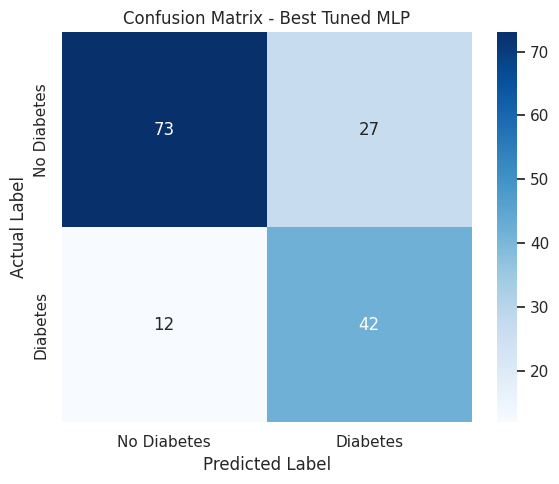

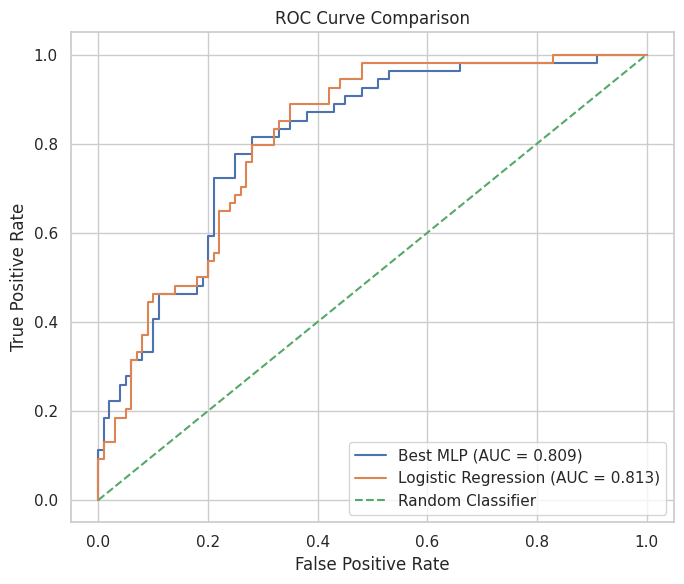

Confusion matrix (baris=aktual, kolom=prediksi): [[73, 27], [12, 42]]


,acc,f1,auc,recall,precision
"MLP baseline [32,16]",0.740,0.623,0.818,0.611,0.635
MLP best (tuned),0.747,0.683,0.809,0.778,0.609
Logistic Regression,0.708,0.545,0.813,0.500,0.600
SVM (RBF),0.734,0.594,0.796,0.556,0.638
Random Forest,0.734,0.602,0.811,0.574,0.633


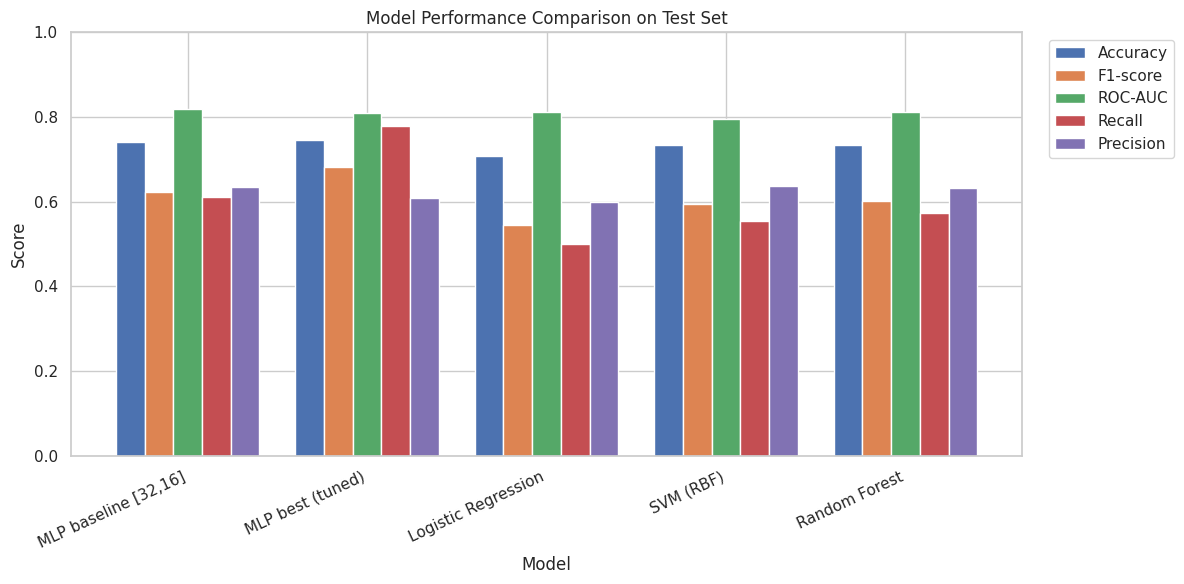

In [15]:
log("E5 final test, fixed seed")

R["final"] = {}
final_seed = 42

def final_metrics(y, p):
    return {k: float(v) for k, v in metrics(y, p).items()}

# 1. MLP baseline
base_mlp = dict(hidden=[32, 16])
p_base, _, _ = train_eval(base_mlp, X_tr, y_tr, X_te, y_te, seed=final_seed)
R["final"]["MLP baseline [32,16]"] = final_metrics(y_te, p_base)

# 2. MLP terbaik hasil random search
p_best, _, _ = train_eval(best_cfg, X_tr, y_tr, X_te, y_te, seed=final_seed)
R["final"]["MLP best (tuned)"] = final_metrics(y_te, p_best)

# 3. Model pembanding pada test set yang sama
a, b = prep(X_tr, X_te)
sk_p = {}
sk_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF)": SVC(probability=True, random_state=0),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=0),
}
for name, model in sk_models.items():
    model.fit(a, y_tr)
    p = model.predict_proba(b)[:, 1]
    sk_p[name] = p
    R["final"][name] = final_metrics(y_te, p)

# 4. Confusion matrix dari MLP tuned
yh = (p_best >= 0.5).astype(int)
R["confusion"] = confusion_matrix(y_te, yh, labels=[0, 1]).tolist()

# Visualisasi 3: Confusion matrix model MLP terbaik

cm = np.array(R["confusion"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix - Best Tuned MLP")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/confusion_matrix.png", dpi=300)
plt.show()

# 5. ROC curve
fpr, tpr, _ = roc_curve(y_te, p_best)
R["roc_best"] = {"fpr": fpr.tolist(), "tpr": tpr.tolist()}
fpr_lr, tpr_lr, _ = roc_curve(y_te, sk_p["Logistic Regression"])
R["roc_lr"] = {"fpr": fpr_lr.tolist(), "tpr": tpr_lr.tolist()}


# Visualisasi 4: ROC curve

auc_best = roc_auc_score(y_te, p_best)
auc_lr = roc_auc_score(y_te, sk_p["Logistic Regression"])

plt.figure(figsize=(7, 6))
plt.plot(
    R["roc_best"]["fpr"],
    R["roc_best"]["tpr"],
    label=f"Best MLP (AUC = {auc_best:.3f})"
)
plt.plot(
    R["roc_lr"]["fpr"],
    R["roc_lr"]["tpr"],
    label=f"Logistic Regression (AUC = {auc_lr:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/roc_curve.png", dpi=300)
plt.show()

print("Confusion matrix (baris=aktual, kolom=prediksi):", R["confusion"])

final_df = pd.DataFrame.from_dict(R["final"], orient="index")
display(final_df.round(3))


# Visualisasi 1: Perbandingan performa model pada test set

final_df = pd.DataFrame.from_dict(R["final"], orient="index")

metrics_to_plot = ["acc", "f1", "auc", "recall", "precision"]

ax = final_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Model Performance Comparison on Test Set")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
ax.legend(
    ["Accuracy", "F1-score", "ROC-AUC", "Recall", "Precision"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/model_comparison.png", dpi=300,
            bbox_inches="tight")
plt.show()

## Learning curve (best config, fold 0)

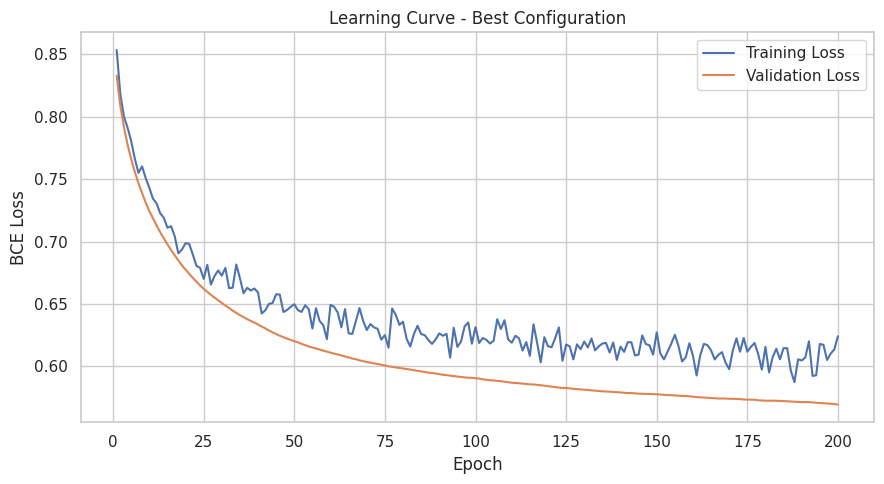

In [16]:
tr, va = FOLDS[0]

_, hist, _ = train_eval(
    best_cfg,
    X_tr[tr], y_tr[tr],
    X_tr[va], y_tr[va],
    seed=0,
    track=True
)

R["curve"] = hist


# Visualisasi 2: Training loss vs validation loss

curve_df = pd.DataFrame(
    R["curve"],
    columns=["Training Loss", "Validation Loss"]
)

plt.figure(figsize=(9, 5))
plt.plot(curve_df.index + 1, curve_df["Training Loss"],
         label="Training Loss")
plt.plot(curve_df.index + 1, curve_df["Validation Loss"],
         label="Validation Loss")

plt.title("Learning Curve - Best Configuration")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/learning_curve.png", dpi=300)
plt.show()


## Permutation Feature Importance

Permutation importance dihitung menggunakan model MLP tuned
yang sama pada test set. Setiap fitur diacak sebanyak 10 kali,
kemudian rata-rata penurunan ROC-AUC digunakan sebagai ukuran
pentingnya fitur bagi prediksi model.

[  1594s] importance Pregnancies 0.0167
[  1594s] importance Glucose 0.1334
[  1594s] importance BloodPressure -0.0051
[  1594s] importance SkinThickness 0.0015
[  1594s] importance Insulin 0.0042
[  1594s] importance BMI 0.0302
[  1594s] importance DiabetesPedigreeFunction 0.0066
[  1594s] importance Age 0.0131


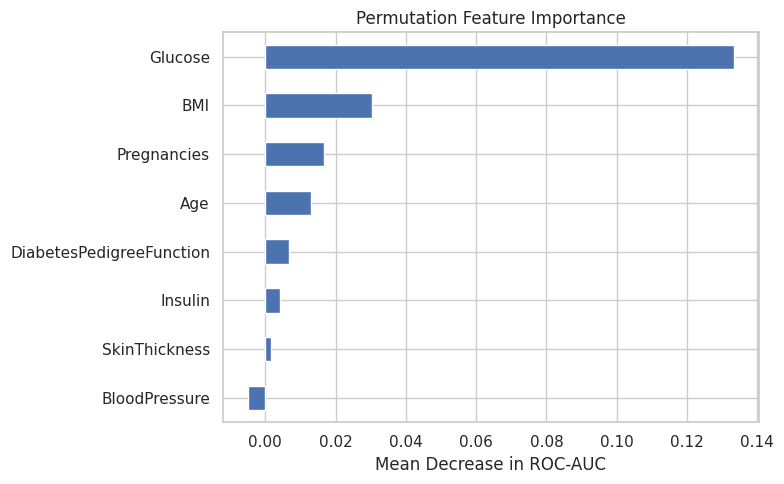

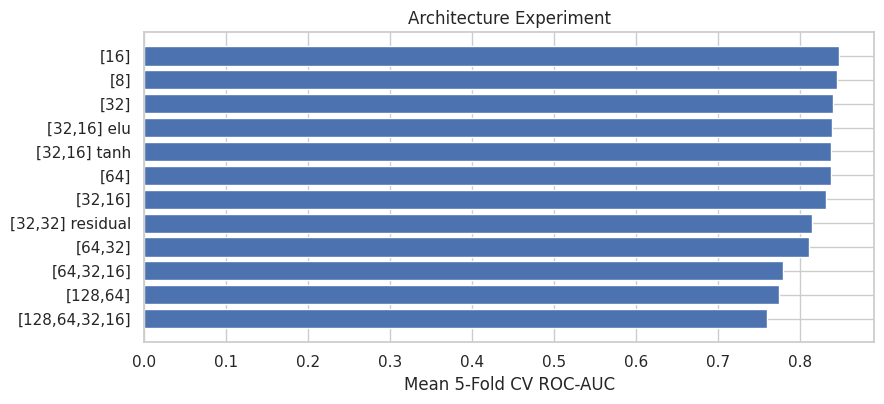

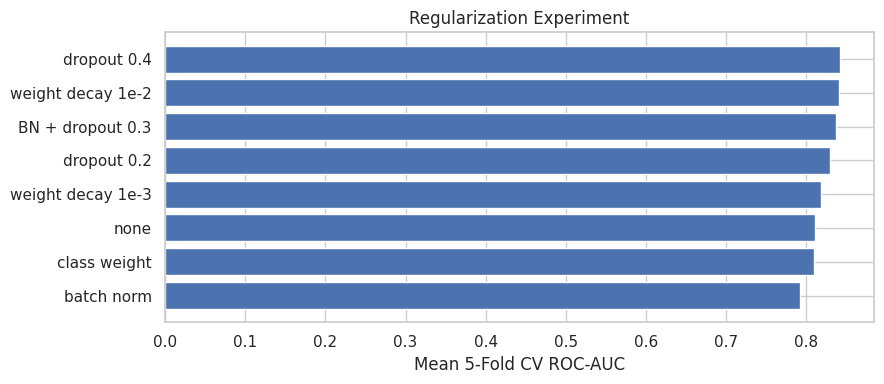

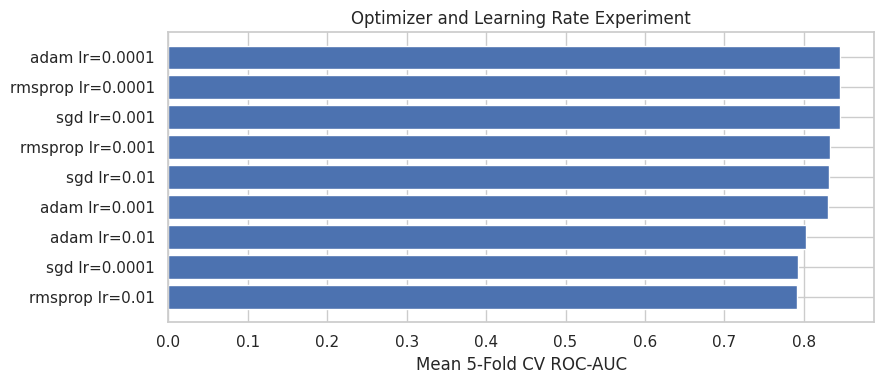

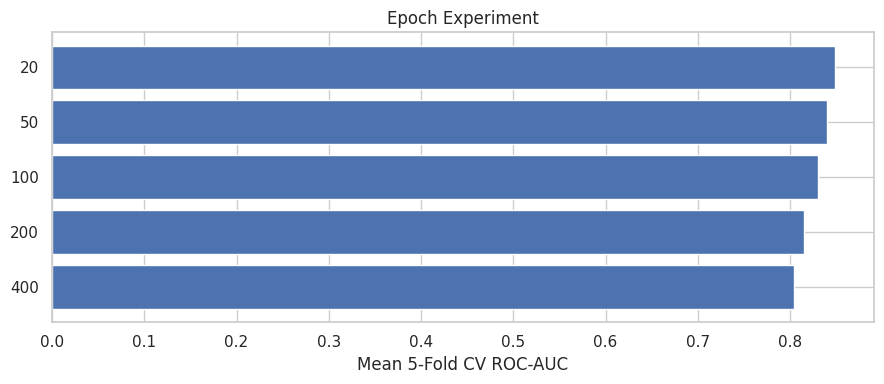

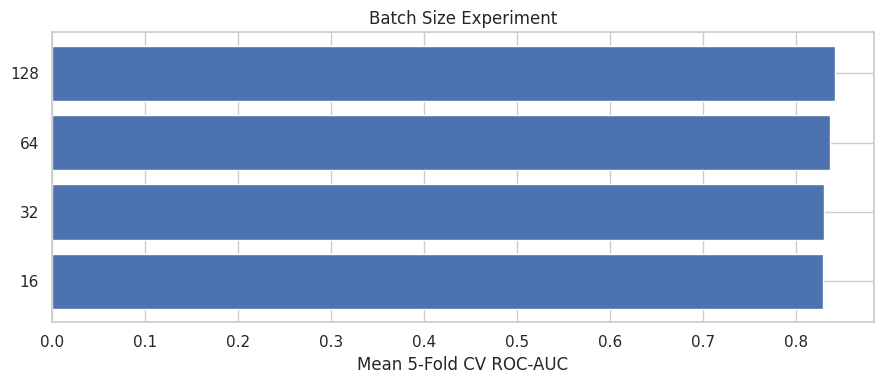

In [17]:
# Permutation Feature Importance
# Model dan preprocessing tetap sama untuk semua fitur

p0, _, model = train_eval(
    best_cfg, X_tr, y_tr, X_te, y_te, seed=42
)
base_auc = roc_auc_score(y_te, p0)

# Fit preprocessing hanya menggunakan data training
imp_pre = SimpleImputer(strategy="median").fit(X_tr)
sc_pre = StandardScaler().fit(
    imp_pre.transform(X_tr)
)

def transform_features(X):
    X_imp = imp_pre.transform(X)
    X_scaled = sc_pre.transform(X_imp)
    return X_scaled.astype(np.float32)

# Model sudah dilatih oleh train_eval
model.eval()

imp = {}
feat = COLS[:-1]
rs = np.random.RandomState(0)

for j, f in enumerate(feat):
    drops = []

    for _ in range(10):
        Xp = X_te.copy()

        # Acak satu fitur tanpa mengubah fitur lainnya
        Xp[:, j] = rs.permutation(Xp[:, j])

        # Gunakan preprocessing yang sama dengan model dasar
        Xp_scaled = transform_features(Xp)
        Xp_tensor = torch.tensor(
            Xp_scaled, dtype=torch.float32
        )

        # Prediksi menggunakan model yang sama
        with torch.no_grad():
            logits = model(Xp_tensor)
            pp = torch.sigmoid(logits).numpy()

        drops.append(
            base_auc - roc_auc_score(y_te, pp)
        )

    imp[f] = float(np.mean(drops))
    log("importance", f, round(imp[f], 4))

R["importance"] = imp

# Visualisasi 6: Permutation feature importance

importance_df = pd.Series(R["importance"]).sort_values()

plt.figure(figsize=(8, 5))
importance_df.plot(kind="barh")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/feature_importance.png", dpi=300)
plt.show()

pd.Series(imp).sort_values(ascending=False)

# Visualisasi 5: Eksperimen arsitektur dan regularisasi

def plot_experiment(results, title, filename):
    df_plot = pd.DataFrame({
        name: {"AUC": value["auc"][0]}
        for name, value in results.items()
    }).T.sort_values("AUC", ascending=True)

    plt.figure(figsize=(9, max(4, len(df_plot) * 0.35)))
    plt.barh(df_plot.index, df_plot["AUC"])
    plt.xlabel("Mean 5-Fold CV ROC-AUC")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{filename}", dpi=300)
    plt.show()

plot_experiment(
    R["arch"],
    "Architecture Experiment",
    "architecture_auc.png"
)

plot_experiment(
    R["reg"],
    "Regularization Experiment",
    "regularization_auc.png"
)

plot_experiment(
    R["opt"],
    "Optimizer and Learning Rate Experiment",
    "optimizer_auc.png"
)

plot_experiment(
    R["epochs"],
    "Epoch Experiment",
    "epochs_auc.png"
)

plot_experiment(
    R["bs"],
    "Batch Size Experiment",
    "batch_size_auc.png"
)

## Simpan & download hasil

In [18]:
# Simpan seluruh hasil eksperimen
with open(f"{OUT}/results.json", "w") as f:
    json.dump(R, f, indent=1)

log("Hasil eksperimen tersimpan.")

# Buat arsip hasil dan grafik
import shutil

zip_path = shutil.make_archive(
    "results",
    "zip",
    OUT
)

print("File hasil:", zip_path)

# Download otomatis jika dijalankan di Google Colab
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print(
        "Notebook tidak berjalan di Google Colab. "
        "File ZIP tersimpan di direktori kerja."
    )

log("DONE")

[  1598s] Hasil eksperimen tersimpan.
File hasil: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[  1598s] DONE
